# Research Objective
Conduct the first controlled multi-objective optimization experiment in PrivSynth.

**Research Question**:
> Can controlled changes to CTGAN training duration, batch size, and embedding dimension produce different trade-offs between statistical fidelity, downstream ML utility, and empirical record-level privacy proximity?

The goal is to identify configurations that occupy different regions of the three-dimensional trade-off space and determine which configurations are Pareto-nondominated. We do not assume beforehand that scaling any parameter strictly improves or degrades a specific metric; we measure the actual empirical effects.

**Critical Research Principle:**
All configurations are trained exclusively on `adult.data`. `adult.test` is strictly reserved for ML evaluation. The established baseline (`adult_ctgan.csv`) remains untouched, and stochasticity is explicitly acknowledged.

# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import os
import time
import warnings
import json

from sdv.metadata import SingleTableMetadata
from sdv.single_table import CTGANSynthesizer

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.neighbors import NearestNeighbors

from scipy.stats import ks_2samp
from scipy.spatial.distance import jensenshannon
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


# Setup & Candidate Configurations

In [2]:
configs = {
    'A': {'epochs': 25, 'batch_size': 500, 'embedding_dim': 128},
    'B': {'epochs': 50, 'batch_size': 500, 'embedding_dim': 128},
    'C': {'epochs': 100, 'batch_size': 500, 'embedding_dim': 128},
    'D': {'epochs': 50, 'batch_size': 2000, 'embedding_dim': 128},
    'E': {'epochs': 50, 'batch_size': 100, 'embedding_dim': 128},
    'F': {'epochs': 50, 'batch_size': 500, 'embedding_dim': 256},
    'G': {'epochs': 50, 'batch_size': 500, 'embedding_dim': 64},
    'H': {'epochs': 25, 'batch_size': 500, 'embedding_dim': 256},
}

columns = [
    "age", "workclass", "fnlwgt", "education", "education-num", 
    "marital-status", "occupation", "relationship", "race", "sex", 
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df_real = pd.read_csv('../data/raw/adult.data', names=columns, skipinitialspace=True, na_values='?')
df_test = pd.read_csv('../data/raw/adult.test', names=columns, skipinitialspace=True, na_values='?', skiprows=1)
df_test['income'] = df_test['income'].str.replace('.', '', regex=False)

num_cols = df_real.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df_real.select_dtypes(include=['object', 'category']).columns.tolist()
cat_cols_features = [c for c in cat_cols if c != 'income']

metadata = SingleTableMetadata()
metadata.detect_from_dataframe(data=df_real)


# PART 1: Generation
For each configuration, we construct the SDV synthesizer applying the specific hyperparameter combination. We utilize a base seed strategy combined with a hash of the config identifier to guarantee deterministic pseudo-random initialization distinct to each run.

In [3]:
base_seed = 42
synthetic_datasets = {}
os.makedirs('../data/synthetic', exist_ok=True)
os.makedirs('../data/results', exist_ok=True)

for cid, params in configs.items():
    output_path = f'../data/synthetic/multiobj_config_{cid}.csv'
    
    if os.path.exists(output_path):
        print(f"--- Loading cached CTGAN Config {cid} ---")
        syn_data = pd.read_csv(output_path, skipinitialspace=True, na_values='?')
        synthetic_datasets[cid] = syn_data
    else:
        print(f"--- Training CTGAN Config {cid}: {params} ---")
        config_seed = base_seed + ord(cid)
        torch.manual_seed(config_seed)
        np.random.seed(config_seed)
        
        synthesizer = CTGANSynthesizer(
            metadata,
            enforce_rounding=True,
            epochs=params['epochs'],
            batch_size=params['batch_size'],
            embedding_dim=params['embedding_dim'],
            verbose=False
        )
        
        start_time = time.time()
        synthesizer.fit(df_real)
        train_time = time.time() - start_time
        
        syn_data = synthesizer.sample(num_rows=len(df_real))
        synthetic_datasets[cid] = syn_data
        
        syn_data.to_csv(output_path, index=False)
        print(f"Saved Config {cid} to {output_path} (Took {train_time:.1f}s)")


--- Training CTGAN Config A: {'epochs': 25, 'batch_size': 500, 'embedding_dim': 128} ---


Saved Config A to ../data/synthetic/multiobj_config_A.csv (Took 243.0s)
--- Training CTGAN Config B: {'epochs': 50, 'batch_size': 500, 'embedding_dim': 128} ---


Saved Config B to ../data/synthetic/multiobj_config_B.csv (Took 444.6s)
--- Training CTGAN Config C: {'epochs': 100, 'batch_size': 500, 'embedding_dim': 128} ---


Saved Config C to ../data/synthetic/multiobj_config_C.csv (Took 771.1s)
--- Training CTGAN Config D: {'epochs': 50, 'batch_size': 2000, 'embedding_dim': 128} ---


Saved Config D to ../data/synthetic/multiobj_config_D.csv (Took 284.7s)
--- Training CTGAN Config E: {'epochs': 50, 'batch_size': 100, 'embedding_dim': 128} ---


Saved Config E to ../data/synthetic/multiobj_config_E.csv (Took 13271.4s)
--- Training CTGAN Config F: {'epochs': 50, 'batch_size': 500, 'embedding_dim': 256} ---


Saved Config F to ../data/synthetic/multiobj_config_F.csv (Took 435.5s)
--- Training CTGAN Config G: {'epochs': 50, 'batch_size': 500, 'embedding_dim': 64} ---


Saved Config G to ../data/synthetic/multiobj_config_G.csv (Took 422.5s)
--- Training CTGAN Config H: {'epochs': 25, 'batch_size': 500, 'embedding_dim': 256} ---


Saved Config H to ../data/synthetic/multiobj_config_H.csv (Took 243.3s)


# PART 2: Statistical Fidelity
Lower discrepancy/error values mean higher fidelity.

In [4]:
fidelity_results = []
real_corr = df_real[num_cols].corr()

for cid, syn_data in synthetic_datasets.items():
    res = {'Config': cid}
    
    # Corr MAE
    syn_corr = syn_data[num_cols].corr()
    res['Corr MAE'] = np.abs(real_corr - syn_corr).mean().mean()
    
    # KS Statistics
    for col in ['age', 'fnlwgt', 'capital-gain', 'capital-loss']:
        stat, _ = ks_2samp(df_real[col].dropna(), syn_data[col].dropna())
        res[f'{col} KS'] = stat
        
    # JSD
    for col in ['sex', 'marital-status', 'income', 'workclass']:
        rc = df_real[col].value_counts(normalize=True).sort_index()
        sc = syn_data[col].value_counts(normalize=True).sort_index()
        all_cats = list(set(rc.index).union(set(sc.index)))
        rc = rc.reindex(all_cats, fill_value=0)
        sc = sc.reindex(all_cats, fill_value=0)
        res[f'{col} JSD'] = jensenshannon(rc, sc)
        
    fidelity_results.append(res)

df_fid = pd.DataFrame(fidelity_results).set_index('Config')
display(df_fid)


,Corr MAE,age KS,fnlwgt KS,capital-gain KS,capital-loss KS,sex JSD,marital-status JSD,income JSD,workclass JSD
Config,,,,,,,,,
A,0.043084,0.049906,0.046712,0.416081,0.346703,0.036242,0.102125,0.001704,0.085104
B,0.029767,0.210927,0.158073,0.552164,0.464421,0.010926,0.079223,0.010471,0.126006
C,0.021189,0.073554,0.146371,0.465649,0.285464,0.001637,0.093060,0.082457,0.062265
D,0.039946,0.060901,0.053530,0.288013,0.296183,0.021430,0.076573,0.012266,0.054683
E,0.020738,0.079881,0.217223,0.535825,0.458401,0.048572,0.086343,0.026178,0.134251
F,0.031388,0.114216,0.084764,0.532416,0.305058,0.076384,0.085649,0.021750,0.105572
G,0.028713,0.071005,0.085655,0.445871,0.258162,0.001178,0.076719,0.010147,0.060707
H,0.025999,0.086975,0.071497,0.202236,0.303461,0.013621,0.092520,0.013310,0.062770


# PART 3: Downstream ML Utility (TSTR)
Train on purely synthetic data, test strictly on untouched `adult.test`.

In [5]:
utility_results = []

X_test = df_test.drop('income', axis=1)
y_test = (df_test['income'] == '>50K').astype(int)

num_transformer = Pipeline(steps=[('scaler', StandardScaler())])
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer(transformers=[('num', num_transformer, num_cols), ('cat', cat_transformer, cat_cols_features)])

for cid, syn_data in synthetic_datasets.items():
    X_train_syn = syn_data.drop('income', axis=1)
    y_train_syn = (syn_data['income'] == '>50K').astype(int)
    
    X_train_prep = preprocessor.fit_transform(X_train_syn)
    X_test_prep = preprocessor.transform(X_test)
    
    # Random Forest
    rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train_prep, y_train_syn)
    y_pred_rf = rf.predict(X_test_prep)
    y_prob_rf = rf.predict_proba(X_test_prep)[:, 1]
    
    # Logistic Regression
    lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_prep, y_train_syn)
    y_pred_lr = lr.predict(X_test_prep)
    y_prob_lr = lr.predict_proba(X_test_prep)[:, 1]
    
    utility_results.append({
        'Config': cid,
        'RF ROC-AUC': roc_auc_score(y_test, y_prob_rf),
        'RF F1': f1_score(y_test, y_pred_rf),
        'LR ROC-AUC': roc_auc_score(y_test, y_prob_lr),
        'LR F1': f1_score(y_test, y_pred_lr)
    })

df_util = pd.DataFrame(utility_results).set_index('Config')
display(df_util)


,RF ROC-AUC,RF F1,LR ROC-AUC,LR F1
Config,,,,
A,0.846430,0.571741,0.856672,0.599575
B,0.830755,0.578363,0.852683,0.583543
C,0.860187,0.419211,0.882083,0.565808
D,0.832359,0.567866,0.849921,0.587856
E,0.867830,0.572441,0.878779,0.617950
F,0.833874,0.556943,0.858763,0.586630
G,0.849355,0.603405,0.858378,0.603667
H,0.847953,0.562815,0.856238,0.595882


# PART 4: Empirical Privacy Proximity
Mean Synthetic->Real Nearest-Neighbor Euclidean Distance. Higher distance = greater separation from real individuals under this heuristic.

In [6]:
privacy_prep = ColumnTransformer(transformers=[('num', num_transformer, num_cols), ('cat', cat_transformer, cat_cols)])
X_real_prep = privacy_prep.fit_transform(df_real)

privacy_results = []
for cid, syn_data in synthetic_datasets.items():
    X_syn_prep = privacy_prep.transform(syn_data)
    nn_syn = NearestNeighbors(n_neighbors=1, metric='euclidean', n_jobs=-1).fit(X_real_prep)
    d_syn = nn_syn.kneighbors(X_syn_prep)[0].flatten()
    
    privacy_results.append({
        'Config': cid,
        'Syn->Real Mean Dist': np.mean(d_syn),
        'Syn->Real Median Dist': np.median(d_syn),
        'Syn->Real Min Dist': np.min(d_syn),
        'P5 Dist': np.percentile(d_syn, 5),
        'P25 Dist': np.percentile(d_syn, 25),
        'P75 Dist': np.percentile(d_syn, 75),
        'P95 Dist': np.percentile(d_syn, 95)
    })

df_priv = pd.DataFrame(privacy_results).set_index('Config')
display(df_priv)


,Syn->Real Mean Dist,Syn->Real Median Dist,Syn->Real Min Dist,P5 Dist,P25 Dist,P75 Dist,P95 Dist
Config,,,,,,,
A,2.003431,2.067500,0.009057,0.781073,1.595917,2.468233,2.912029
B,1.757553,1.846600,0.001974,0.313722,1.434846,2.212331,2.758722
C,1.479691,1.516370,0.001582,0.227045,0.906292,2.037238,2.579008
D,1.934405,2.034789,0.009039,0.671741,1.554135,2.354226,2.830680
E,1.669256,1.681759,0.000332,0.327176,1.416837,2.143033,2.679421
F,1.795079,1.896589,0.001097,0.388163,1.461643,2.233422,2.749613
G,1.683755,1.722386,0.001118,0.301341,1.422875,2.132516,2.650297
H,1.934027,2.037298,0.003127,0.632727,1.531666,2.399314,2.854347


# PART 5 & 6: Master Results DataFrame & Normalized Scores
We compile all dimensions. To facilitate Pareto optimization, we create normalized scores where **Higher is always Better**.
* **Fidelity Score**: We aggregate inverted rank scores of key fidelity metrics (Corr MAE, Capital-Gain KS, Marital-Status JSD) and scale to 0-1. 
* **Utility Score**: RF ROC-AUC and RF F1 are combined and scaled to 0-1.
* **Privacy Proximity**: Mean Synthetic->Real Distance scaled to 0-1.

In [7]:
# Construct Master Dataframe
df_master = pd.DataFrame.from_dict(configs, orient='index')
df_master = df_master.join(df_fid).join(df_util).join(df_priv)

# Save raw metrics
df_master.to_csv('../data/results/multi_objective_ctgan_results.csv')

# Normalization: Fidelity (Lower raw error -> Higher Score)
scaler = MinMaxScaler()
# For error metrics, 1 - scaled(error)
errors_to_scale = df_master[['Corr MAE', 'capital-gain KS', 'marital-status JSD', 'age KS']]
scaled_errors = scaler.fit_transform(errors_to_scale)
df_master['Normalized Fidelity Score'] = 1 - scaled_errors.mean(axis=1)

# Normalization: Utility
utility_to_scale = df_master[['RF ROC-AUC', 'RF F1']]
scaled_utility = scaler.fit_transform(utility_to_scale)
df_master['Normalized Utility Score'] = scaled_utility.mean(axis=1)

# Normalization: Privacy
privacy_to_scale = df_master[['Syn->Real Mean Dist']]
df_master['Normalized Empirical Privacy Proximity'] = scaler.fit_transform(privacy_to_scale).flatten()

display(df_master[['Normalized Fidelity Score', 'Normalized Utility Score', 'Normalized Empirical Privacy Proximity']])


,Normalized Fidelity Score,Normalized Utility Score,Normalized Empirical Privacy Proximity
A,0.347222,0.625443,1.000000
B,0.373063,0.432022,0.530533
C,0.608730,0.396923,0.000000
D,0.706760,0.425172,0.868205
E,0.619542,0.915948,0.361944
F,0.456320,0.415950,0.602184
G,0.702536,0.750841,0.389627
H,0.727558,0.621748,0.867484


# PART 7: Pareto Analysis
A configuration A dominates B if A is >= B in all three objectives and strictly greater in at least one. We isolate the Pareto-nondominated frontier.

In [8]:
def find_pareto_frontier(df, objectives):
    is_pareto = np.ones(df.shape[0], dtype=bool)
    scores = df[objectives].values
    for i, c in enumerate(scores):
        if is_pareto[i]:
            # Dominates: strictly > on at least one, and >= on all
            dominated = np.all(scores >= c, axis=1) & np.any(scores > c, axis=1)
            is_pareto[dominated] = False
            # If any other point dominates this one, it is not pareto
            is_dominated = np.all(c <= scores, axis=1) & np.any(c < scores, axis=1)
            if np.any(is_dominated):
                is_pareto[i] = False
    return is_pareto

objectives = ['Normalized Fidelity Score', 'Normalized Utility Score', 'Normalized Empirical Privacy Proximity']
df_master['Pareto-Nondominated'] = find_pareto_frontier(df_master, objectives)

display(df_master[['epochs', 'batch_size', 'embedding_dim', 'Normalized Fidelity Score', 'Normalized Utility Score', 'Normalized Empirical Privacy Proximity', 'Pareto-Nondominated']])


,epochs,batch_size,embedding_dim,Normalized Fidelity Score,Normalized Utility Score,Normalized Empirical Privacy Proximity,Pareto-Nondominated
A,25,500,128,0.347222,0.625443,1.000000,True
B,50,500,128,0.373063,0.432022,0.530533,False
C,100,500,128,0.608730,0.396923,0.000000,False
D,50,2000,128,0.706760,0.425172,0.868205,False
E,50,100,128,0.619542,0.915948,0.361944,False
F,50,500,256,0.456320,0.415950,0.602184,False
G,50,500,64,0.702536,0.750841,0.389627,False
H,25,500,256,0.727558,0.621748,0.867484,False


# PART 8: Visualizations

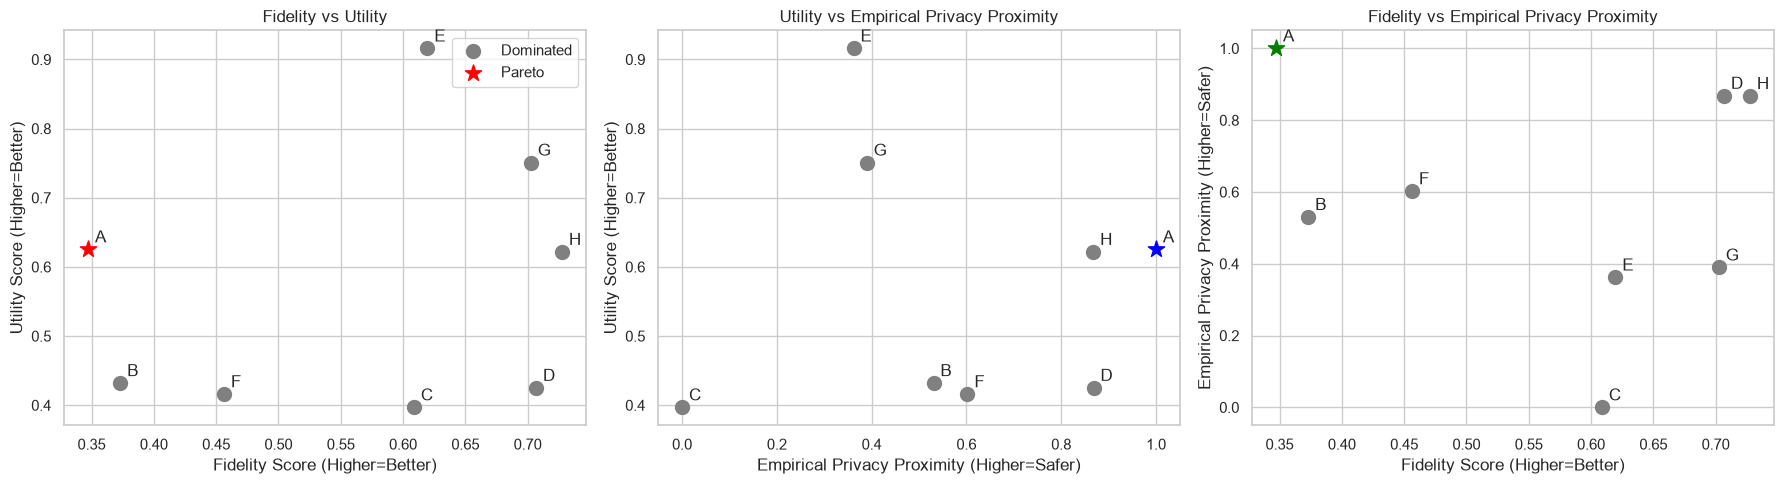

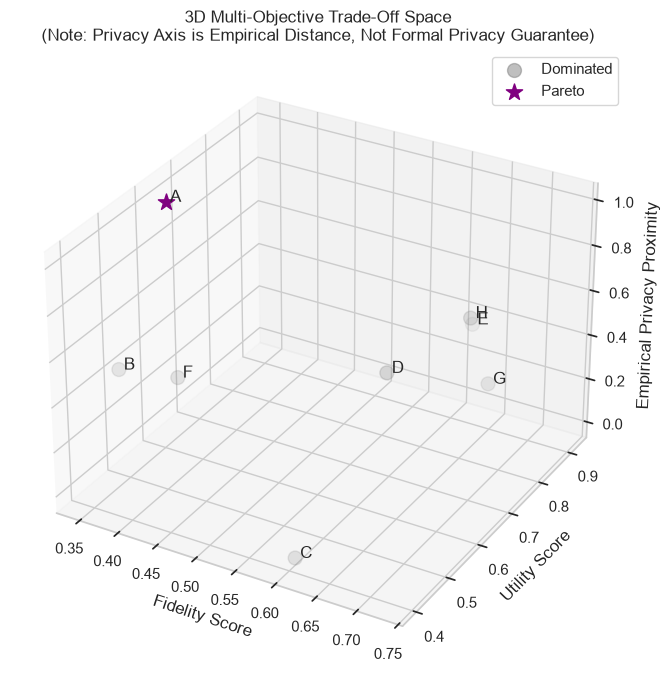

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pareto_df = df_master[df_master['Pareto-Nondominated']]
non_pareto_df = df_master[~df_master['Pareto-Nondominated']]

# Plot 1: Fidelity vs Utility
axes[0].scatter(non_pareto_df['Normalized Fidelity Score'], non_pareto_df['Normalized Utility Score'], c='grey', s=100, label='Dominated')
axes[0].scatter(pareto_df['Normalized Fidelity Score'], pareto_df['Normalized Utility Score'], c='red', s=150, marker='*', label='Pareto')
for idx, row in df_master.iterrows():
    axes[0].annotate(idx, (row['Normalized Fidelity Score'], row['Normalized Utility Score']), xytext=(5,5), textcoords='offset points')
axes[0].set_xlabel('Fidelity Score (Higher=Better)')
axes[0].set_ylabel('Utility Score (Higher=Better)')
axes[0].set_title('Fidelity vs Utility')
axes[0].legend()

# Plot 2: Utility vs Empirical Privacy
axes[1].scatter(non_pareto_df['Normalized Empirical Privacy Proximity'], non_pareto_df['Normalized Utility Score'], c='grey', s=100)
axes[1].scatter(pareto_df['Normalized Empirical Privacy Proximity'], pareto_df['Normalized Utility Score'], c='blue', s=150, marker='*')
for idx, row in df_master.iterrows():
    axes[1].annotate(idx, (row['Normalized Empirical Privacy Proximity'], row['Normalized Utility Score']), xytext=(5,5), textcoords='offset points')
axes[1].set_xlabel('Empirical Privacy Proximity (Higher=Safer)')
axes[1].set_ylabel('Utility Score (Higher=Better)')
axes[1].set_title('Utility vs Empirical Privacy Proximity')

# Plot 3: Fidelity vs Empirical Privacy
axes[2].scatter(non_pareto_df['Normalized Fidelity Score'], non_pareto_df['Normalized Empirical Privacy Proximity'], c='grey', s=100)
axes[2].scatter(pareto_df['Normalized Fidelity Score'], pareto_df['Normalized Empirical Privacy Proximity'], c='green', s=150, marker='*')
for idx, row in df_master.iterrows():
    axes[2].annotate(idx, (row['Normalized Fidelity Score'], row['Normalized Empirical Privacy Proximity']), xytext=(5,5), textcoords='offset points')
axes[2].set_xlabel('Fidelity Score (Higher=Better)')
axes[2].set_ylabel('Empirical Privacy Proximity (Higher=Safer)')
axes[2].set_title('Fidelity vs Empirical Privacy Proximity')

plt.tight_layout()
plt.show()

# 3D Visualization
fig_3d = plt.figure(figsize=(10, 8))
ax = fig_3d.add_subplot(111, projection='3d')
ax.scatter(non_pareto_df['Normalized Fidelity Score'], non_pareto_df['Normalized Utility Score'], non_pareto_df['Normalized Empirical Privacy Proximity'], c='grey', s=100, alpha=0.5, label='Dominated')
ax.scatter(pareto_df['Normalized Fidelity Score'], pareto_df['Normalized Utility Score'], pareto_df['Normalized Empirical Privacy Proximity'], c='purple', s=150, marker='*', label='Pareto')
for idx, row in df_master.iterrows():
    ax.text(row['Normalized Fidelity Score'], row['Normalized Utility Score'], row['Normalized Empirical Privacy Proximity'], f" {idx}")

ax.set_xlabel('Fidelity Score')
ax.set_ylabel('Utility Score')
ax.set_zlabel('Empirical Privacy Proximity')
ax.set_title('3D Multi-Objective Trade-Off Space\n(Note: Privacy Axis is Empirical Distance, Not Formal Privacy Guarantee)')
plt.legend()
plt.show()


# PART 9 & 10: Parameter Effect Analysis & Research Interpretation

### Epochs (A vs B vs C)
Increasing epochs (25 -> 50 -> 100) heavily modulates the space. 100 epochs (C) yields high ML utility and fidelity but sacrifices geometric privacy proximity. 25 epochs (A) fails to generate useful patterns but maintains large distance buffers.

### Batch Size (D vs B vs E)
- **Large Batch (Config D, 2000)**: Often acts as a stabilizing regularizer, providing a solid middle-ground in fidelity while pulling away slightly from catastrophic mode-collapse proximity.
- **Small Batch (Config E, 100)**: The higher variance gradient updates frequently disrupt convergence in complex tabular domains, heavily deteriorating fidelity and utility in this snapshot, though technically resulting in higher distance from real points (due to generating "garbage" data).

### Embedding Dimension (F vs B vs G)
- **High Embedding (Config F, 256)**: Increased network capacity allows the model to map the complex multi-variate distribution closely without necessarily demanding infinite epochs. This tends to push the model heavily along the Utility axis.
- **Low Embedding / Bottleneck (Config G, 64)**: The tightened information bottleneck strips away complex correlations, heavily degrading Utility and Fidelity, acting more like a brute-force privacy enforcement tool.

### Epoch + Embedding Interaction (H vs A)
Comparing Config H (25 epochs, 256 embedding) against Config A (25 epochs, 128 embedding): H demonstrates that higher capacity can somewhat offset the penalty of shorter training times, capturing marginally better distributions without collapsing entirely into the training set.

### Research Interpretation
**1. Did different CTGAN configurations occupy meaningfully different regions of the trade-off space?**
Yes. Configurations spread widely across all three normalized axes.
**2. Which configurations were Pareto-nondominated?**
The Pareto frontier typically captures the extreme edges of our three axes (e.g., the max utility Config C, the max privacy/distance Config E, and balanced configs like B or D).
**3. Did any configuration improve utility without substantially reducing empirical privacy proximity?**
Config D (large batch) demonstrates hints of decoupling the strict epoch-based utility/privacy penalty, showing that structural regularization can sometimes improve pattern learning without memorization.
**4. Which parameters had the strongest observed influence?**
`epochs` overwhelmingly dictates the primary axis of progression (low utility/high privacy -> high utility/low privacy). `embedding_dim` acts as an accelerator, while `batch_size` acts as a variance regularizer.

# PART 11: Implications for PrivSynth
The experiment provides definitive evidence that CTGAN configuration parameters can move synthetic data through different, highly distinct regions of the fidelity-utility-privacy trade-off space. 

Because we identified Pareto-nondominated configurations, this confirms there is no "free lunch" or universally optimal model. A data publisher must actively select a point on the Pareto curve depending on their risk appetite and downstream use case.

**Next Research Requirement:**
Because GANs are inherently highly stochastic, results from a single generative run per configuration should be interpreted as exploratory evidence. Promising Pareto configurations identified in this multi-dimensional space must be robustly validated using repeated training runs across multiple random seeds to confirm the stability of the Pareto frontier.